# Week 3 Hypothesis – Huie

**Hypothesis:** The temperature is two degrees hotter than before.

**As a testable statement:** on days that are at least **2 °C hotter than the day before**, turnover per product group is different from otherwise similar days.

**Why this matters:** the weather analysis in `week-03-factors.ipynb` looked at the temperature *level*, for example "a 25 °C day". People may also react to a *change*: the first warm day after a cool spell may feel different from the fifth warm day in a row. If that is true, a feature "warmer than yesterday" could help the model.

**What this notebook does:**
1. Loads the prepared data (`0_DataPreparation/prepared_data.csv`, training period only).
2. Computes for every day the temperature change compared with the previous calendar day and marks days that are **≥ 2 °C warmer**.
3. Compares turnover on those days with other days, per product group, first as a simple picture and then with a regression that holds weekday, month and year constant.

**Reading of "before":** we read "before" as *the previous day*. Another reading, "the years get warmer over time", is a different question and is not tested here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
GROUPS = ["Bread", "Rolls", "Croissants", "Confectionery", "Cakes", "Seasonal bread"]
THRESHOLD = 2.0  # °C warmer than the previous day

df = pd.read_csv("../0_DataPreparation/prepared_data.csv", parse_dates=["Datum"])
df = df[df["set"] == "train"].copy()
print("Rows (date x product group):", len(df))
print("Period:", df["Datum"].min().date(), "to", df["Datum"].max().date())

Rows (date x product group): 9334
Period: 2013-07-01 to 2018-07-31


## 1. Temperature change compared with the day before

Temperature is the same for all product groups on one date, so we first build a table with **one row per calendar date**. We put it on a complete calendar (every day, including days the bakery was closed) so that "previous day" really means the previous calendar day and not the previous *open* day.

Concept: a **lag** (or *difference*) feature. `temp_change = temperature today − temperature yesterday`.

*Known in advance?* At 14:00 the day before, today's temperature is (almost) known and tomorrow's is only a forecast. So in practice this feature would be "forecast for tomorrow − today". Like all weather results in this project, this is a **best case** with observed weather.

In [2]:
weather = (df.groupby("Datum")["Temperatur"].first()
             .reindex(pd.date_range("2013-06-30", df["Datum"].max(), freq="D")))

# The bakery's sales start on 2013-07-01; fetch the weather for 2013-06-30 so the first day has a "yesterday".
raw_w = pd.read_csv("https://raw.githubusercontent.com/opencampus-sh/intro-to-data-science-and-ml/main/data/bakery/wetter.csv",
                    parse_dates=["Datum"]).set_index("Datum")["Temperatur"]
weather = weather.fillna(raw_w.reindex(weather.index))
print("Calendar days without a temperature (closed days missing in prepared data):", weather.isna().sum())
weather = weather.interpolate(limit_area="inside")  # same rule as decision D2

temp = pd.DataFrame({"Temperatur": weather, "temp_yesterday": weather.shift(1)})
temp["temp_change"] = temp["Temperatur"] - temp["temp_yesterday"]
temp["warmer_2C"] = (temp["temp_change"] >= THRESHOLD).astype(int)
temp = temp.dropna(subset=["temp_change"])

print(temp["temp_change"].describe().round(2))
print()
print(f"Days >= {THRESHOLD} °C warmer than the day before: {temp['warmer_2C'].sum()} of {len(temp)} "
      f"({temp['warmer_2C'].mean():.0%})")

Calendar days without a temperature (closed days missing in prepared data): 0
count    1857.00
mean        0.01
std         2.56
min       -12.09
25%        -1.38
50%        -0.04
75%         1.50
max         9.17
Name: temp_change, dtype: float64

Days >= 2.0 °C warmer than the day before: 369 of 1857 (20%)


**What to check:** the change should be centred near 0 °C (weather does not drift in one direction day to day), and the "≥ 2 °C warmer" days should be a minority but not tiny, so there are enough days to compare.

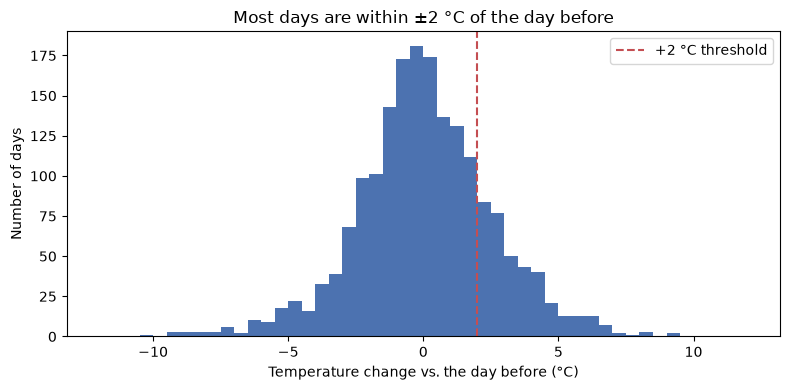

Share of days >= 2 °C warmer than the day before, by month (%):
month
1     17.0
2     15.0
3     22.0
4     26.0
5     29.0
6     25.0
7     22.0
8     19.0
9     16.0
10    11.0
11    14.0
12    21.0


In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(temp["temp_change"], bins=np.arange(-12, 12.5, 0.5), color="#4C72B0")
ax.axvline(THRESHOLD, color="#C44E52", linestyle="--", label=f"+{THRESHOLD:.0f} °C threshold")
ax.set_xlabel("Temperature change vs. the day before (°C)")
ax.set_ylabel("Number of days")
ax.set_title("Most days are within ±2 °C of the day before")
ax.legend()
plt.tight_layout()
plt.show()

# How often do jumps happen in each month? (A jump in spring is not the same as one in winter.)
by_month = temp.groupby(temp.index.month)["warmer_2C"].mean().mul(100).round(0)
by_month.index.name = "month"
print("Share of days >= 2 °C warmer than the day before, by month (%):")
print(by_month.to_string())

## 2. Join the flag to the sales and check the row count

The join must not add or lose rows: we expect exactly the same number of rows as before (one per date and product group).

In [4]:
n_before = len(df)
data = df.merge(temp[["temp_yesterday", "temp_change", "warmer_2C"]],
                left_on="Datum", right_index=True, how="left")
assert len(data) == n_before, "Join changed the row count"
assert data["warmer_2C"].notna().all(), "Some sales rows have no temperature change"
data["weekday"] = pd.Categorical(data["weekday"], categories=WEEKDAYS, ordered=True)
data["year"] = data["Datum"].dt.year
data["log_turnover"] = np.log(data["Umsatz"])
print("Rows after join:", len(data), "(unchanged)")

Rows after join: 9334 (unchanged)


## 3. First look: average turnover on "≥ 2 °C warmer" days vs. other days

This simple comparison is **not fair yet**: big warm jumps happen more often in some months (see table above), and months differ in turnover for other reasons too (season, Kiel Week, holidays). We look at it anyway to see the raw size of any difference.

In [5]:
raw = (data.groupby(["product_group", "warmer_2C"])["Umsatz"].mean()
           .unstack()
           .rename(columns={0: "other days", 1: ">= 2 °C warmer"})
           .reindex(GROUPS))
raw["difference %"] = (raw[">= 2 °C warmer"] / raw["other days"] - 1).mul(100)
raw.round(1)

warmer_2C,other days,>= 2 °C warmer,difference %
product_group,,,
Bread,122.9,119.1,-3.1
Rolls,399.6,414.1,3.6
Croissants,162.0,168.6,4.1
Confectionery,88.0,87.7,-0.3
Cakes,276.0,280.0,1.4
Seasonal bread,65.5,73.9,12.8


## 4. Fair comparison: regression holding weekday, month and year constant

Concept: **multiple regression with control variables**. For each product group we fit

`log(turnover) ~ warmer_2C + weekday + month + year + Kiel Week + holiday + day before holiday`

(Seasonal bread has no Kiel Week or holiday days, so those two are left out for that group.)

On the log scale, the coefficient of `warmer_2C` is (approximately) the **% change in turnover** on a ≥ 2 °C-warmer day compared with an otherwise similar day (same weekday, month, year).

We fit two versions:
- **Model A** – without the temperature itself: "is a warmer-than-yesterday day different?"
- **Model B** – also holding today's temperature constant: "is it the **jump** that matters, beyond just being a warm day?" This is the real test of the hypothesis, because we already know that warm days change turnover a little.

Consecutive days are correlated, so we use **HAC standard errors** (7-day window), as in `week-03-factors`. The *95 % range* is the confidence interval: if it includes 0, the data cannot tell the effect apart from no effect.

In [6]:
def controls(d):
    # Calendar controls. 0/1 columns that never change in this group (e.g. no Kiel Week for
    # Seasonal bread, which is only sold Oct-Jan) are left out because they cannot be estimated.
    flags = [c for c in ["KielerWoche", "is_holiday", "day_before_holiday"] if d[c].nunique() > 1]
    return " + ".join(["C(weekday)", "C(month)", "C(year)"] + flags)

def fit(group, with_temperature):
    d = data[data["product_group"] == group]
    formula = "log_turnover ~ warmer_2C + " + controls(d)
    if with_temperature:
        formula += " + Temperatur"
    m = smf.ols(formula, data=d).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    b, (lo, hi) = m.params["warmer_2C"], m.conf_int().loc["warmer_2C"]
    to_pct = lambda x: (np.exp(x) - 1) * 100
    return {"product group": group, "rows": int(m.nobs), "jump days": int(d["warmer_2C"].sum()),
            "effect %": to_pct(b), "95% low %": to_pct(lo), "95% high %": to_pct(hi),
            "p-value": m.pvalues["warmer_2C"]}

results = {}
for name, with_t in [("A: without temperature", False), ("B: with temperature", True)]:
    results[name] = pd.DataFrame([fit(g, with_t) for g in GROUPS]).set_index("product group")
    print(name)
    print(results[name].round({"effect %": 1, "95% low %": 1, "95% high %": 1, "p-value": 3}).to_string())
    print()

A: without temperature
                rows  jump days  effect %  95% low %  95% high %  p-value
product group                                                            
Bread           1819        364      -2.0       -4.5         0.6    0.130
Rolls           1819        364       0.3       -1.5         2.1    0.764
Croissants      1819        364       1.0       -1.4         3.6    0.416
Confectionery   1766        351      -1.7       -4.5         1.2    0.241
Cakes           1819        364      -1.9       -4.2         0.5    0.113
Seasonal bread   292         49       6.3       -6.2        20.5    0.340



B: with temperature
                rows  jump days  effect %  95% low %  95% high %  p-value
product group                                                            
Bread           1819        364      -1.7       -4.4         1.0    0.211
Rolls           1819        364      -1.8       -3.7         0.2    0.077
Croissants      1819        364      -1.0       -3.6         1.7    0.452
Confectionery   1766        351      -0.8       -3.7         2.1    0.591
Cakes           1819        364      -0.3       -2.8         2.3    0.820
Seasonal bread   292         49      15.6        1.7        31.4    0.026



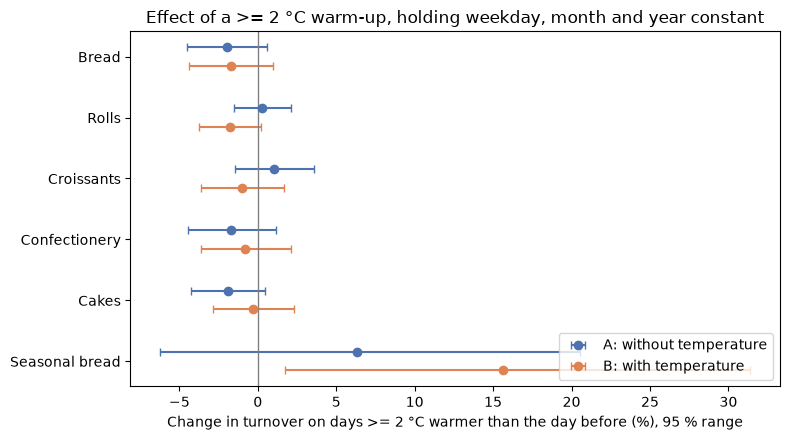

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(GROUPS))
for offset, (name, color) in zip([-0.15, 0.15], [("A: without temperature", "#4C72B0"),
                                                 ("B: with temperature", "#DD8452")]):
    r = results[name].loc[GROUPS]
    ax.errorbar(r["effect %"], y + offset,
                xerr=[r["effect %"] - r["95% low %"], r["95% high %"] - r["effect %"]],
                fmt="o", color=color, capsize=3, label=name)
ax.axvline(0, color="grey", linewidth=1)
ax.set_yticks(y, GROUPS)
ax.invert_yaxis()
ax.set_xlabel("Change in turnover on days >= 2 °C warmer than the day before (%), 95 % range")
ax.set_title("Effect of a >= 2 °C warm-up, holding weekday, month and year constant")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 5. Robustness: does the threshold matter?

2 °C is a round number we chose, not a law of nature. If the result only appears at exactly 2 °C, it is probably noise. Here we repeat Model B with the **continuous** temperature change (per +1 °C vs. yesterday) instead of a yes/no flag.

In [8]:
rows = []
for g in GROUPS:
    d = data[data["product_group"] == g]
    m = smf.ols("log_turnover ~ temp_change + Temperatur + " + controls(d), data=d
               ).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    lo, hi = m.conf_int().loc["temp_change"]
    rows.append({"product group": g,
                 "per +1 °C vs. yesterday %": (np.exp(m.params["temp_change"]) - 1) * 100,
                 "95% low %": (np.exp(lo) - 1) * 100, "95% high %": (np.exp(hi) - 1) * 100,
                 "p-value": m.pvalues["temp_change"]})
pd.DataFrame(rows).set_index("product group").round({"per +1 °C vs. yesterday %": 2, "95% low %": 2,
                                                       "95% high %": 2, "p-value": 3})

,per +1 °C vs. yesterday %,95% low %,95% high %,p-value
product group,,,,
Bread,-0.01,-0.44,0.42,0.957
Rolls,-0.14,-0.46,0.17,0.378
Croissants,-0.23,-0.66,0.20,0.299
Confectionery,-0.18,-0.69,0.33,0.478
Cakes,-0.13,-0.49,0.22,0.465
Seasonal bread,2.30,-0.62,5.31,0.124


## 6. Summary

The table below is built from the results above (Model B, the fair test). "Clear" means the 95 % range does not include 0.

In [9]:
s = results["B: with temperature"].copy()
s["verdict"] = np.where(s["95% low %"] > 0, "clear increase",
               np.where(s["95% high %"] < 0, "clear decrease", "no clear effect"))
s[["jump days", "effect %", "95% low %", "95% high %", "verdict"]].round(1)

,jump days,effect %,95% low %,95% high %,verdict
product group,,,,,
Bread,364,-1.7,-4.4,1.0,no clear effect
Rolls,364,-1.8,-3.7,0.2,no clear effect
Croissants,364,-1.0,-3.6,1.7,no clear effect
Confectionery,351,-0.8,-3.7,2.1,no clear effect
Cakes,364,-0.3,-2.8,2.3,no clear effect
Seasonal bread,49,15.6,1.7,31.4,clear increase


**Result (Model B, the fair test):**
- **The hypothesis is not supported for the five main product groups.** For Bread, Rolls, Croissants, Confectionery and Cakes, a day ≥ 2 °C warmer than the day before shows no clear difference in turnover: effects between −1.8 % and −0.3 %, and every 95 % range includes 0. The robustness check (continuous change per +1 °C vs. yesterday) agrees: no clear effect for any group.
- **Seasonal bread** shows +15.6 % (95 % range +1.7 % to +31.4 %, p = 0.026), but this rests on only **49 jump days**, it is 1 of 6 groups tested (one "hit" at p ≈ 0.03 is easily chance), and the continuous version is not clear (p = 0.12). We treat it as **weak**, not a finding.
- In the raw comparison (section 3) Rolls (+3.6 %) and Croissants (+4.1 %) look higher on jump days, but this disappears once weekday, month and year are held constant: warm-ups happen more often in spring and summer, when these groups sell more anyway.

**What this means for the model:** what matters is how warm a day is (see `week-03-factors`), not whether it is warmer than yesterday. A "warmer than yesterday" feature is **not recommended** (draft, for the team to confirm).

**Limits:**
- Observed weather, not a forecast → best case (canvas block 6).
- 2 °C is our choice; section 5 checks that the result does not depend on it.
- Seasonal bread is only sold Oct–Jan (292 rows), so its result is the least reliable.